# Laboratorio 19 — Redes convolucionales: qué hace un filtro

Una capa convolucional aplica un mismo arreglo chico de pesos, el **filtro**, en todas las
posiciones de una imagen, y produce un **mapa de activación** (*feature map*) que registra
dónde aparece el patrón del filtro y con qué intensidad. Este laboratorio estudia la red
convolucional a través de sus filtros, sin entrar en el diseño de arquitecturas, para
responder una pregunta concreta:

> ¿Qué detecta un filtro, y por qué una red que **aprende** sus propios filtros clasifica
> imágenes mejor que una red densa con muchos más parámetros?

El recorrido tiene cuatro partes. En la primera se implementa la convolución desde cero con
NumPy y se verifica contra PyTorch. En la segunda se aplican filtros diseñados a mano sobre
una fotografía y se aprende a leerlos por sus pesos. En la tercera se diseña un filtro que
detecta un patrón y se comprueban las dos propiedades que distinguen a la convolución: la
equivarianza a la traslación y el bajo número de parámetros. En la cuarta se entrena una red
convolucional mínima sobre Fashion-MNIST y se comprueba que sus filtros son exactamente la
operación implementada en la primera parte.

| Parte | Ejercicio | Qué se escribe | Cómo se cierra |
|---|---|---|---|
| 1. La convolución a mano | 1. Ventana deslizante | `convolucion2d`, `tamano_salida` | **Verificación** contra `torch.nn.functional.conv2d` |
| | 2. Predecir antes de calcular | Dos mapas calculados a mano | **Verificación** contra el ejercicio 1 |
| 2. Galería de filtros | 3. Galería | `filtro_gaussiano` y el diccionario `FILTROS` | **Verificación** de propiedades + figura |
| | 4. Leer un filtro | — (experimento dado) | Preguntas de análisis |
| | 5. Combinar mapas | `relu`, `magnitud_gradiente` | **Verificación** contra `scipy.ndimage.prewitt` |
| 3. El filtro como detector | 6. Diseñar un filtro | Un filtro de $3\times3$ | **Verificación** de selectividad |
| | 7. Pesos compartidos y traslación | `max_pooling`, `parametros_densa`, `parametros_conv` | **Verificación** contra PyTorch + preguntas |
| 4. La red aprende los filtros | 8. Una red convolucional mínima | El conteo de parámetros de las dos redes | **Verificación** contra PyTorch + preguntas |
| | 9. Mirar adentro de la red | `mapas_de_activacion` | **Verificación** contra `convolucion2d` |
| | 10. Filtros fijos contra aprendidos | `filtros_de_la_galeria` | Preguntas de análisis |
| | 11. Traslaciones (opcional) | — (experimento dado) | Preguntas de análisis |

Las celdas que contienen `raise NotImplementedError()` deben completarse; el resto es
andamiaje y se ejecuta sin modificar. Después de cada bloque de preguntas hay una celda
**Respuesta** que debe completarse con lo observado: los números del propio notebook son la
evidencia. Duración estimada: dos horas.

**Notación.** La de las notas: el filtro $\mathbf W$ tiene lado $r$, el paso (*stride*) es
$s$ y el relleno (*padding*) es $q$; la imagen de entrada tiene lado $d$ y el mapa de salida,
lado $d_1$. Las posiciones se indexan desde $0$. **Se dice *filtro*, no *kernel***: la palabra
*kernel* ya nombra a $K(\mathbf x,\mathbf x')$ en las máquinas de vectores de soporte, aunque
las bibliotecas llamen `kernel_size` al lado del filtro.

## 0. Preparación

In [1]:
from __future__ import annotations

import math
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cbook
from matplotlib.colors import LinearSegmentedColormap
from scipy import ndimage

import torch
import torch.nn.functional as F
from torch import nn

SEMILLA = 42
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

AZUL, TURQUESA, NARANJA = "#19326E", "#50ACB0", "#CD742A"
VIOLETA, OLIVA, GRIS = "#A3477F", "#89A943", "#8A8A8A"

# Respuestas positivas en turquesa, negativas en naranja, cero en blanco.
DIVERGENTE = LinearSegmentedColormap.from_list("divergente", [NARANJA, "white", TURQUESA])

torch.set_num_threads(4)
torch.set_num_interop_threads(1)

### Funciones de visualización

`mostrar` dibuja una grilla de mapas. Un mapa con valores negativos se dibuja con la escala
divergente (positivo en turquesa, negativo en naranja, cero en blanco); uno sin negativos,
en escala de grises. `mostrar_matrices` dibuja matrices chicas con sus valores escritos en
cada celda.

In [2]:
#@title Funciones de visualización (ejecutar sin modificar) { display-mode: "form" }
def mostrar(mapas: list[np.ndarray], titulos: list[str], columnas: int = 4,
            escala_comun: bool = False, lado: float = 2.6) -> None:
    """Dibuja `mapas` en una grilla de `columnas` columnas."""
    filas = math.ceil(len(mapas) / columnas)
    fig, ejes = plt.subplots(filas, columnas, figsize=(lado * columnas, lado * filas),
                             squeeze=False)
    v_comun = max(float(np.abs(m).max()) for m in mapas) or 1.0
    for eje, mapa, titulo in zip(ejes.flat, mapas, titulos):
        v = v_comun if escala_comun else (float(np.abs(mapa).max()) or 1.0)
        if mapa.min() < 0:
            eje.imshow(mapa, cmap=DIVERGENTE, vmin=-v, vmax=v)
        else:
            eje.imshow(mapa, cmap="gray", vmin=0, vmax=v)
        eje.set_title(titulo, fontsize=9)
        eje.axis("off")
    for eje in ejes.flat[len(mapas):]:
        eje.axis("off")
    plt.tight_layout()
    plt.show()


def mostrar_matrices(matrices: list[np.ndarray], titulos: list[str]) -> None:
    """Dibuja matrices chicas con el valor de cada celda escrito encima."""
    fig, ejes = plt.subplots(1, len(matrices), figsize=(3.2 * len(matrices), 3.2))
    for eje, M, titulo in zip(np.atleast_1d(ejes), matrices, titulos):
        v = float(np.abs(M).max()) or 1.0
        eje.imshow(M, cmap=DIVERGENTE, vmin=-v, vmax=v)
        for (i, j), valor in np.ndenumerate(M):
            eje.text(j, i, f"{valor:g}", ha="center", va="center", fontsize=9)
        eje.set_title(titulo, fontsize=10)
        eje.set_xticks(range(M.shape[1]))
        eje.set_yticks(range(M.shape[0]))
    plt.tight_layout()
    plt.show()

### La fotografía

La parte 2 trabaja sobre el retrato de Grace Hopper que se distribuye con `matplotlib`
(dominio público, Marina de los Estados Unidos), el mismo de las notas. Se pasa a escala de
grises con valores en $[0,1]$ y se submuestrea a la mitad para que la convolución escrita
con bucles corra en pocos segundos.

Forma de la fotografía: (300, 256)   rango: 0.001 a 1.0


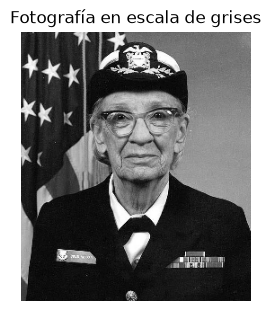

In [3]:
with cbook.get_sample_data("grace_hopper.jpg") as archivo:
    foto_color = plt.imread(archivo)

FOTO = foto_color.mean(axis=2)[::2, ::2] / 255.0
print("Forma de la fotografía:", FOTO.shape, "  rango:", FOTO.min().round(3), "a", FOTO.max().round(3))

plt.figure(figsize=(3, 3.5))
plt.imshow(FOTO, cmap="gray")
plt.title("Fotografía en escala de grises")
plt.axis("off")
plt.show()

---

# Parte 1 — La convolución a mano

## Ejercicio 1 — La ventana deslizante

Una unidad convolucional calcula la misma suma ponderada que una unidad densa, pero sobre
una ventana chica de la entrada. Con un único canal, el valor del mapa en la posición
$[u,v]$ es

$$
z[u,v]=b+\sum_{u'=0}^{r-1}\sum_{v'=0}^{r-1}w[u',v']\;a[su+u',\,sv+v'] ,
$$

donde $a$ es la entrada **después** de agregarle $q$ filas y columnas de ceros en cada
borde. Es una **correlación cruzada**: el filtro no se invierte, igual que en PyTorch.

El número de posiciones en que el filtro entra completo en la entrada rellenada da el lado
de la salida (derivación en § 2.2 de las notas):

$$
d_1=\left\lfloor\frac{d+2q-r}{s}\right\rfloor+1 .
$$

Corresponde implementar las dos funciones. La convolución se escribe con dos bucles sobre
las posiciones de salida $[u,v]$; dentro del bucle, la ventana se extrae con un corte del
arreglo y la suma de productos se calcula con NumPy. La entrada puede ser rectangular; el
filtro es cuadrado.

In [4]:
def tamano_salida(d: int, r: int, s: int = 1, q: int = 0) -> int:
    """Lado del mapa de salida de una convolución o de un pooling.

    Parámetros
    ----------
    d : lado de la entrada (sin relleno).
    r : lado del filtro o de la ventana.
    s : paso.
    q : relleno, en filas y columnas de ceros por borde.

    Devuelve
    --------
    int con d_1 = floor((d + 2q - r) / s) + 1.
    """
    if min(d, r, s) <= 0 or q < 0 or d + 2*q < r:
        raise ValueError("Dimensiones, paso o relleno no válidos.")
    return (d + 2*q - r) // s + 1


def convolucion2d(A: np.ndarray, W: np.ndarray, b: float = 0.0,
                  s: int = 1, q: int = 0) -> np.ndarray:
    """Correlación cruzada 2D de una entrada de un canal con un filtro, más un sesgo.

    Parámetros
    ----------
    A : arreglo de forma (n_filas, n_columnas), la entrada.
    W : arreglo de forma (r, r), el filtro.
    b : sesgo, sumado en todas las posiciones.
    s : paso, el mismo en filas y en columnas.
    q : relleno con ceros, el mismo en los cuatro bordes.

    Devuelve
    --------
    Z : arreglo de forma (tamano_salida(n_filas, r, s, q), tamano_salida(n_columnas, r, s, q))
        con Z[u, v] = b + sum_{u', v'} W[u', v'] * A_rellenada[s*u + u', s*v + v'].
    """
    A, W = np.asarray(A, dtype=float), np.asarray(W, dtype=float)
    if A.ndim != 2 or W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError("La entrada debe ser 2D y el filtro cuadrado.")
    r = W.shape[0]
    nf, nc = tamano_salida(A.shape[0], r, s, q), tamano_salida(A.shape[1], r, s, q)
    rellenada = np.pad(A, ((q, q), (q, q)), mode="constant")
    Z = np.empty((nf, nc), dtype=float)
    for u in range(nf):
        for v in range(nc):
            ventana = rellenada[s*u:s*u+r, s*v:s*v+r]
            Z[u, v] = b + np.sum(W * ventana)
    return Z

La verificación compara contra `torch.nn.functional.conv2d`, que implementa la misma
correlación cruzada. PyTorch espera arreglos de cuatro ejes, `(lote, canales, filas,
columnas)`: la función auxiliar agrega los dos primeros.

In [5]:
# VERIFICACIÓN
def conv2d_pytorch(A: np.ndarray, W: np.ndarray, b: float = 0.0, s: int = 1, q: int = 0) -> np.ndarray:
    """La misma operación, calculada por PyTorch (referencia)."""
    salida = F.conv2d(torch.from_numpy(A)[None, None], torch.from_numpy(W)[None, None],
                      bias=torch.tensor([b], dtype=torch.float64), stride=s, padding=q)
    return salida[0, 0].numpy()


rng = np.random.default_rng(SEMILLA)
for (n_f, n_c), r, s, q in [((8, 8), 3, 1, 0), ((7, 9), 3, 2, 1), ((10, 6), 5, 1, 2),
                            ((11, 11), 3, 3, 0), ((6, 13), 2, 2, 0)]:
    A = rng.normal(size=(n_f, n_c))
    W = rng.normal(size=(r, r))
    b = float(rng.normal())
    Z = convolucion2d(A, W, b, s, q)
    Z_ref = conv2d_pytorch(A, W, b, s, q)
    assert Z.shape == (tamano_salida(n_f, r, s, q), tamano_salida(n_c, r, s, q)), \
        f"forma {Z.shape}: no coincide con tamano_salida"
    assert Z.shape == Z_ref.shape, f"forma {Z.shape}, PyTorch da {Z_ref.shape}"
    assert np.allclose(Z, Z_ref), f"valores distintos con r={r}, s={s}, q={q}"
    print(f"entrada {n_f}x{n_c}, r={r}, s={s}, q={q}  ->  salida {Z.shape}  coincide con PyTorch")

print("\nconvolucion2d y tamano_salida verificadas.")

entrada 8x8, r=3, s=1, q=0  ->  salida (6, 6)  coincide con PyTorch
entrada 7x9, r=3, s=2, q=1  ->  salida (4, 5)  coincide con PyTorch
entrada 10x6, r=5, s=1, q=2  ->  salida (10, 6)  coincide con PyTorch
entrada 11x11, r=3, s=3, q=0  ->  salida (3, 3)  coincide con PyTorch
entrada 6x13, r=2, s=2, q=0  ->  salida (3, 6)  coincide con PyTorch

convolucion2d y tamano_salida verificadas.


Un primer uso: el escalón $6\times6$ de las notas (§ 2.3), con unos en las columnas $0$–$2$ y
ceros en las columnas $3$–$5$, y el filtro de Prewitt vertical.

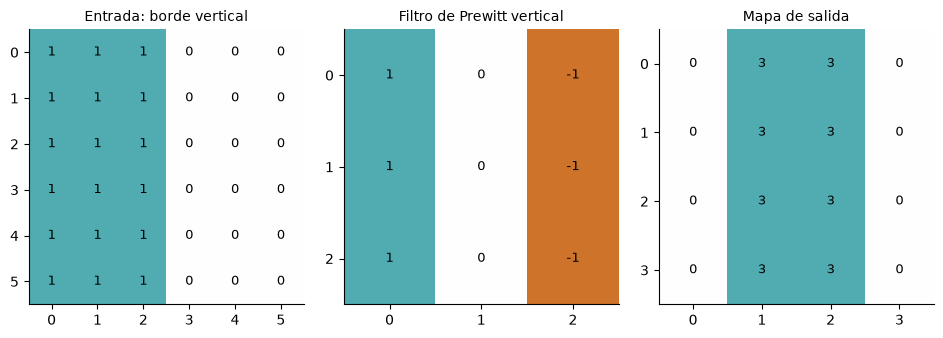

In [6]:
ESCALON = np.zeros((6, 6))
ESCALON[:, :3] = 1.0
PREWITT_V = np.array([[1.0, 0.0, -1.0],
                      [1.0, 0.0, -1.0],
                      [1.0, 0.0, -1.0]])

mostrar_matrices([ESCALON, PREWITT_V, convolucion2d(ESCALON, PREWITT_V)],
                 ["Entrada: borde vertical", "Filtro de Prewitt vertical", "Mapa de salida"])

## Ejercicio 2 — Predecir antes de calcular

La entrada de $5\times5$ y el filtro en forma de X de la figura de § 2.1 de las notas:

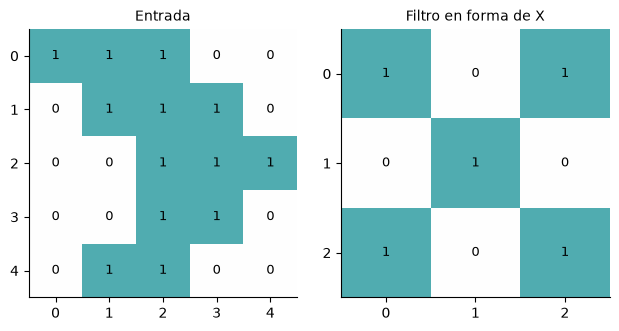

In [7]:
A_X = np.array([[1, 1, 1, 0, 0],
                [0, 1, 1, 1, 0],
                [0, 0, 1, 1, 1],
                [0, 0, 1, 1, 0],
                [0, 1, 1, 0, 0]], dtype=float)
W_X = np.array([[1, 0, 1],
                [0, 1, 0],
                [1, 0, 1]], dtype=float)

mostrar_matrices([A_X, W_X], ["Entrada", "Filtro en forma de X"])

Corresponde calcular **a mano, sin ejecutar `convolucion2d`**, los dos mapas de salida:

- `Z_mano_s1_q0`: con paso $s=1$ y sin relleno.
- `Z_mano_s2_q1`: con paso $s=2$ y relleno $q=1$.

Antes de escribir los valores, determinar el lado de cada mapa con la fórmula de $d_1$. Los
valores se escriben como literales en un `np.array`; no se calculan con código.

In [8]:
# d_1 = floor((5 - 3)/1) + 1 = 3.
Z_mano_s1_q0 = np.array([[4, 3, 4], [2, 4, 3], [2, 3, 4]], dtype=float)
# d_1 = floor((5 + 2 - 3)/2) + 1 = 3.
Z_mano_s2_q1 = np.array([[2, 3, 1], [1, 4, 3], [0, 2, 1]], dtype=float)
# Ejemplo s=1, q=0: Z[0,0] = 1 + 1 + 1 + 0 + 1 = 4.
# Ejemplo s=2, q=1: Z[0,0] = 0 + 0 + 1 + 0 + 1 = 2.

s=1, q=0: el cálculo a mano coincide.
s=2, q=1: el cálculo a mano coincide.


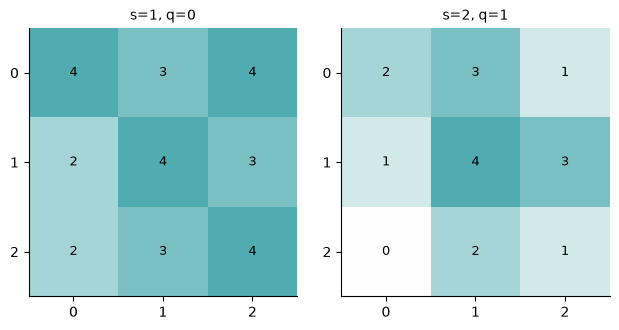

In [9]:
# VERIFICACIÓN
for nombre, Z_mano, s, q in [("s=1, q=0", Z_mano_s1_q0, 1, 0), ("s=2, q=1", Z_mano_s2_q1, 2, 1)]:
    Z = convolucion2d(A_X, W_X, s=s, q=q)
    assert np.shape(Z_mano) == Z.shape, f"{nombre}: la forma correcta es {Z.shape}"
    errores = np.argwhere(~np.isclose(Z_mano, Z))
    assert errores.size == 0, f"{nombre}: posiciones con error {errores.tolist()}"
    print(f"{nombre}: el cálculo a mano coincide.")

mostrar_matrices([convolucion2d(A_X, W_X), convolucion2d(A_X, W_X, s=2, q=1)],
                 ["s=1, q=0", "s=2, q=1"])

### Para analizar

1. El valor máximo posible del filtro en forma de X sobre una entrada binaria es $5$. ¿Qué
   forma tiene que tener una ventana para alcanzarlo? ¿Qué indican las posiciones del mapa
   con valor $4$?
2. ¿Cuántas posiciones de salida produciría el filtro sobre esta entrada con $s=1$ y $q=1$?
   ¿Qué valor de $q$ conserva el lado de la entrada para un filtro de lado $r$ impar, y por
   qué los filtros suelen tener lado impar?

**Respuesta:**

1. Alcanza 5 si los cinco lugares de la X son 1. Las otras cuatro posiciones pueden ser 0 o 1: el filtro tiene peso cero allí, por lo que no distingue una X aislada de una ventana completamente blanca. Un 4 indica que cuatro de esos cinco lugares contienen 1; no demuestra una X completa.
2. Con s=1 y q=1 produce 5×5=25 valores. Para lado impar r, q=(r−1)/2 conserva el tamaño con paso 1. Un lado impar tiene centro único y permite padding simétrico entero; con lado par se necesitaría relleno asimétrico para conservar exactamente el tamaño.

---

# Parte 2 — Galería de filtros

## Ejercicio 3 — La galería

Antes de que las redes aprendieran sus filtros, el procesamiento de imágenes los diseñaba a
mano. Corresponde construir el diccionario `FILTROS` con ocho filtros clásicos, todos de
$3\times3$ salvo el gaussiano:

| Nombre | Descripción de los pesos |
|---|---|
| `identidad` | $1$ en el centro y $0$ en el resto |
| `promedio` | Los nueve pesos iguales, y la suma es $1$ |
| `gaussiano` | `filtro_gaussiano(5, 1.0)`: un $5\times5$ con pesos que decaen con la distancia al centro |
| `realce` | $5$ en el centro, $-1$ en los cuatro vecinos de arriba, abajo, izquierda y derecha, $0$ en las esquinas |
| `prewitt_vertical` | El filtro de Prewitt vertical de las notas (§ 2.3): columna de unos, columna de ceros, columna de menos unos |
| `prewitt_horizontal` | Su transpuesto |
| `laplaciano` | $-4$ en el centro, $1$ en los cuatro vecinos directos, $0$ en las esquinas |
| `relieve` | Primera fila $(-2,-1,0)$, segunda $(-1,1,1)$, tercera $(0,1,2)$ |

El filtro gaussiano de lado $r$ y desvío $\sigma$ tiene, en la posición $[u',v']$, el peso

$$
w[u',v']=\frac{1}{Z}\exp\!\left(-\frac{(u'-c)^2+(v'-c)^2}{2\sigma^2}\right),\qquad c=\frac{r-1}{2},
$$

donde $Z$ es la constante que hace que los pesos sumen $1$.

In [10]:
def filtro_gaussiano(r: int, sigma: float) -> np.ndarray:
    """Filtro gaussiano de lado r, centrado, con pesos que suman 1.

    Parámetros
    ----------
    r     : lado del filtro (impar).
    sigma : desvío estándar, en píxeles.

    Devuelve
    --------
    W : arreglo de forma (r, r) con W[u', v'] proporcional a
        exp(-((u' - c)**2 + (v' - c)**2) / (2 sigma**2)), c = (r - 1) / 2, y W.sum() == 1.
    """
    if r <= 0 or r % 2 == 0 or sigma <= 0:
        raise ValueError("r debe ser positivo e impar; sigma debe ser positivo.")
    posiciones = np.arange(r) - (r - 1)/2
    u, v = np.meshgrid(posiciones, posiciones, indexing="ij")
    W = np.exp(-(u*u + v*v) / (2*sigma*sigma))
    return W / W.sum()


FILTROS: dict[str, np.ndarray] = {
    "identidad": np.array([[0., 0., 0.], [0., 1., 0.], [0., 0., 0.]]),
    "promedio": np.ones((3, 3), dtype=float) / 9,
    "gaussiano": filtro_gaussiano(5, 1.0),
    "realce": np.array([[0., -1., 0.], [-1., 5., -1.], [0., -1., 0.]]),
    "prewitt_vertical": PREWITT_V.copy(),
    "prewitt_horizontal": PREWITT_V.T.copy(),
    "laplaciano": np.array([[0., 1., 0.], [1., -4., 1.], [0., 1., 0.]]),
    "relieve": np.array([[-2., -1., 0.], [-1., 1., 1.], [0., 1., 2.]]),
}

In [11]:
# VERIFICACIÓN
from scipy.signal.windows import gaussian

assert list(FILTROS) == ["identidad", "promedio", "gaussiano", "realce", "prewitt_vertical",
                         "prewitt_horizontal", "laplaciano", "relieve"], "faltan filtros o cambió el orden"
for nombre, W in FILTROS.items():
    assert isinstance(W, np.ndarray) and W.ndim == 2 and W.shape[0] == W.shape[1], \
        f"{nombre}: debe ser un arreglo cuadrado"

g_ref = np.outer(gaussian(5, 1.0), gaussian(5, 1.0))
assert np.allclose(filtro_gaussiano(5, 1.0), g_ref / g_ref.sum()), "filtro_gaussiano: no coincide con scipy"
assert np.isclose(filtro_gaussiano(7, 2.0).sum(), 1.0), "filtro_gaussiano: los pesos deben sumar 1"

suma_esperada = {"identidad": 1, "promedio": 1, "gaussiano": 1, "realce": 1,
                 "prewitt_vertical": 0, "prewitt_horizontal": 0, "laplaciano": 0, "relieve": 1}
for nombre, suma in suma_esperada.items():
    assert np.isclose(FILTROS[nombre].sum(), suma), f"{nombre}: los pesos deberían sumar {suma}"
assert np.allclose(FILTROS["prewitt_horizontal"], FILTROS["prewitt_vertical"].T)
assert np.allclose(FILTROS["prewitt_vertical"], PREWITT_V)
assert np.allclose(FILTROS["laplaciano"], FILTROS["laplaciano"].T)
assert FILTROS["realce"][1, 1] == 5 and FILTROS["relieve"][0, 0] == -2

print("Los ocho filtros tienen la forma y la suma de pesos esperadas.")

Los ocho filtros tienen la forma y la suma de pesos esperadas.


La galería aplica cada filtro sobre la fotografía con la `convolucion2d` del ejercicio 1,
con el relleno que conserva el tamaño, $q=(r-1)/2$. Los filtros se muestran arriba y los
mapas abajo. Los mapas de los filtros cuyos pesos suman $1$ se recortan a $[0,1]$ y se
dibujan en grises, como una imagen; los demás, con la escala divergente.

Ocho convoluciones sobre (300, 256): 1.5 s


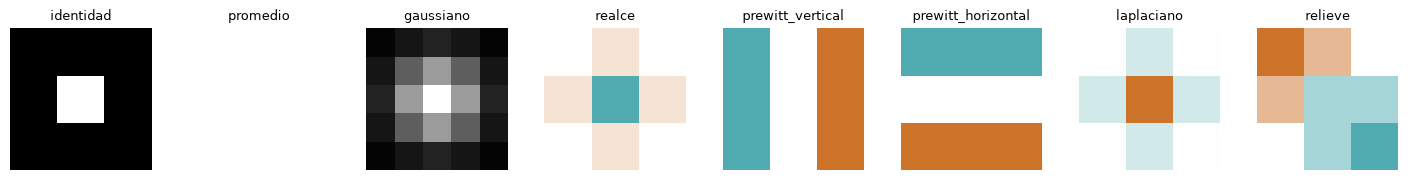

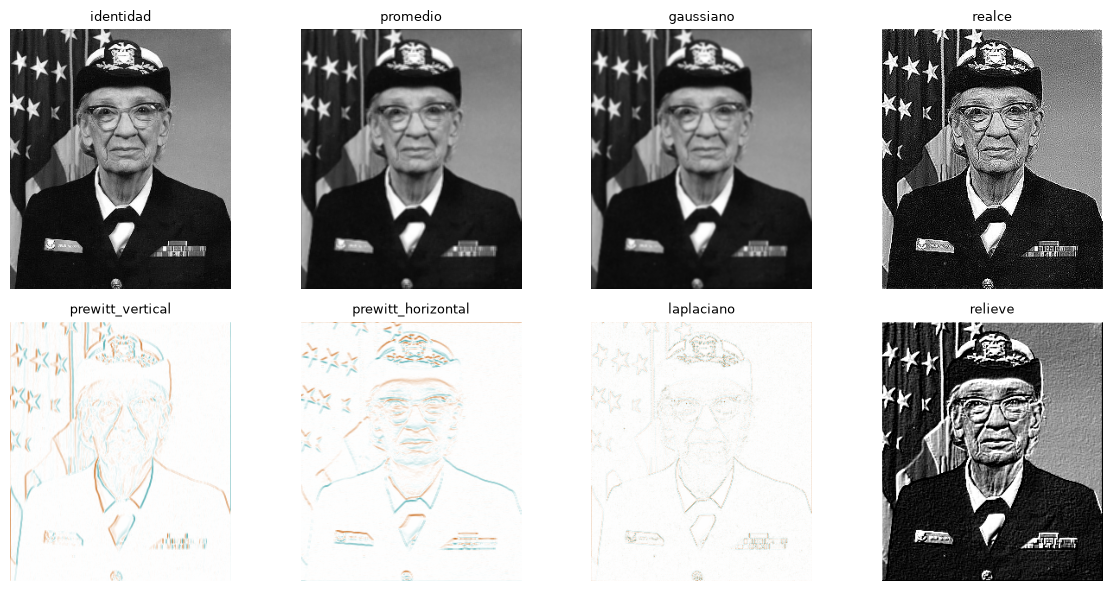

In [12]:
inicio = time.perf_counter()
MAPAS_GALERIA = {nombre: convolucion2d(FOTO, W, q=(W.shape[0] - 1) // 2)
                 for nombre, W in FILTROS.items()}
print(f"Ocho convoluciones sobre {FOTO.shape}: {time.perf_counter() - inicio:.1f} s")

mostrar(list(FILTROS.values()), list(FILTROS), columnas=8, lado=1.8)
mostrar([np.clip(Z, 0, 1) if np.isclose(FILTROS[nombre].sum(), 1) else Z
         for nombre, Z in MAPAS_GALERIA.items()], list(MAPAS_GALERIA), columnas=4, lado=3.0)

## Ejercicio 4 — Leer un filtro

**Un filtro se lee por sus pesos.** Dos propiedades alcanzan para anticipar casi todo lo que
mostró la galería: cuánto suman los pesos y cómo se reparten los signos. El experimento
siguiente mide, para cada filtro, la suma de sus pesos y la media del mapa que produce sobre
la fotografía (lejos de los bordes, donde el relleno con ceros no interviene).

In [13]:
media_foto = FOTO[2:-2, 2:-2].mean()
print(f"Media de la fotografía: {media_foto:.3f}\n")
print(f"{'filtro':<20}{'suma de pesos':>15}{'media del mapa':>17}{'desvío del mapa':>17}")
for nombre, Z in MAPAS_GALERIA.items():
    interior = Z[2:-2, 2:-2]
    print(f"{nombre:<20}{FILTROS[nombre].sum():>15.2f}{interior.mean():>17.3f}{interior.std():>17.3f}")

Media de la fotografía: 0.316

filtro                suma de pesos   media del mapa  desvío del mapa
identidad                      1.00            0.316            0.269
promedio                       1.00            0.316            0.255
gaussiano                      1.00            0.316            0.253
realce                         1.00            0.316            0.415
prewitt_vertical               0.00           -0.002            0.368
prewitt_horizontal             0.00            0.006            0.335
laplaciano                     0.00            0.000            0.246
relieve                        1.00            0.311            0.569


Segundo experimento: el filtro de Prewitt vertical, multiplicado por $-1$ y por $10$. Los
tres mapas se dibujan **con la misma escala de colores**, para que la magnitud sea
comparable.

Prewitt vertical       mínimo   -2.86   máximo    2.97
multiplicado por -1    mínimo   -2.97   máximo    2.86
multiplicado por 10    mínimo  -28.56   máximo   29.69


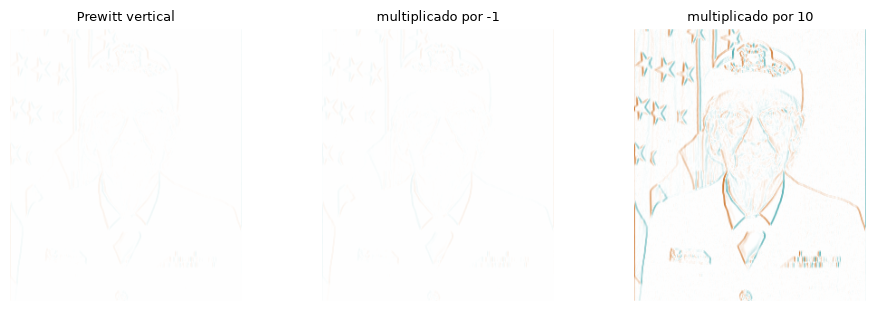

In [14]:
W_v = FILTROS["prewitt_vertical"]
variantes = {"Prewitt vertical": W_v, "multiplicado por -1": -W_v, "multiplicado por 10": 10 * W_v}
mapas_variantes = [convolucion2d(FOTO, W, q=1) for W in variantes.values()]
mostrar(mapas_variantes, list(variantes), columnas=3, escala_comun=True, lado=3.2)
for nombre, Z in zip(variantes, mapas_variantes):
    print(f"{nombre:<22} mínimo {Z.min():>7.2f}   máximo {Z.max():>7.2f}")

### Para analizar

1. En la tabla, ¿qué tienen en común los filtros cuya suma de pesos es $1$, y qué los que
   suman $0$? Explicar con la fórmula de la convolución por qué un filtro cuyos pesos suman
   $0$ da respuesta nula sobre una región de brillo constante.
2. ¿Por qué el filtro de Prewitt vertical responde a los contornos verticales y no a los
   horizontales? ¿Qué significa el signo de su respuesta en términos de la imagen?
3. Multiplicar el filtro por $-1$ y por $10$, ¿cambia **dónde** responde o **cuánto**? En
   una red, ¿qué consecuencia tiene que los pesos del filtro se aprendan sin restricción de
   escala ni de signo?
4. El filtro de realce es la identidad más cuatro veces la diferencia entre el píxel y el
   promedio de sus cuatro vecinos. ¿Por qué esa combinación acentúa los bordes? ¿Qué relación
   tiene con el laplaciano?

**Respuesta:**

1. Los de suma 1 preservan una región constante de brillo c: la salida interior es c·1. Los de suma 0 eliminan esa componente constante y destacan variaciones: sum(W·c)=c·sum(W)=0, con sesgo cero. La media del mapa sobre una foto es aproximadamente la media de entrada por la suma de pesos; no es una identidad exacta para una región recortada y con bordes.
2. El Prewitt vertical resta el lado derecho al izquierdo, sumando sobre tres filas. Responde a cambios de brillo horizontales, que forman contornos verticales. Es positivo si a la izquierda hay más brillo, negativo en el sentido inverso y cero en una región uniforme.
3. Multiplicar por −1 invierte la polaridad y por 10 multiplica todas las respuestas por 10; no mueve los lugares donde el mapa es distinto de cero. Con ReLU, el signo sí cambia qué bordes sobreviven. Aprender pesos permite ajustar orientación, polaridad e intensidad; sus magnitudes por sí solas no miden la importancia de un filtro porque capas posteriores pueden compensarlas.
4. El realce conserva el píxel central y suma su diferencia respecto de los vecinos: 5c−(arriba+abajo+izquierda+derecha). Esa diferencia es grande cerca de bordes y también amplifica ruido. Con el laplaciano definido aquí, W_realce = W_identidad − W_laplaciano.

## Ejercicio 5 — Combinar mapas

Un filtro de Prewitt solo ve bordes en una dirección. Combinando los dos mapas,
$Z_v=\mathbf W_v*A$ y $Z_h=\mathbf W_h*A$, se obtiene la **magnitud del gradiente**

$$
G[u,v]=\sqrt{Z_v[u,v]^2+Z_h[u,v]^2},
$$

que responde a los bordes en cualquier dirección. Y aplicando la función de activación ReLU,
$\operatorname{ReLU}(z)=\max(0,z)$, sobre un mapa, se conservan solo las respuestas
positivas del filtro: un único sentido de cambio.

Corresponde implementar `relu` y `magnitud_gradiente`. La magnitud se calcula con
`convolucion2d`, sin relleno.

In [15]:
def relu(Z: np.ndarray) -> np.ndarray:
    """Función de activación ReLU, elemento a elemento: max(0, z)."""
    return np.maximum(Z, 0)


def magnitud_gradiente(A: np.ndarray) -> np.ndarray:
    """Magnitud del gradiente de A con los dos filtros de Prewitt, sin relleno y con paso 1.

    Parámetros
    ----------
    A : arreglo de forma (n_filas, n_columnas).

    Devuelve
    --------
    G : arreglo de forma (n_filas - 2, n_columnas - 2) con G = sqrt(Z_v**2 + Z_h**2).
    """
    Z_v = convolucion2d(A, FILTROS["prewitt_vertical"])
    Z_h = convolucion2d(A, FILTROS["prewitt_horizontal"])
    return np.hypot(Z_v, Z_h)

La verificación compara contra `scipy.ndimage.prewitt`, que calcula las mismas diferencias
con un signo distinto —irrelevante al elevar al cuadrado— y devuelve un mapa del tamaño de la
entrada. Se comparan solo las posiciones interiores, donde ninguna de las dos
implementaciones depende del tratamiento de los bordes.

relu y magnitud_gradiente verificadas.


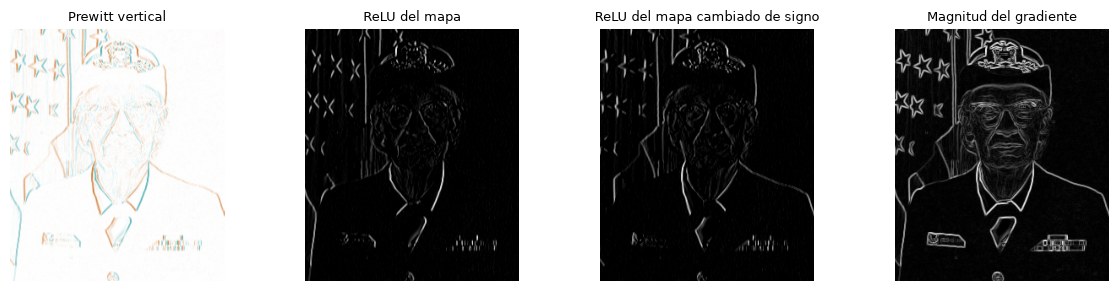

In [16]:
# VERIFICACIÓN
assert np.array_equal(relu(np.array([-2.0, 0.0, 3.0])), np.array([0.0, 0.0, 3.0]))

G = magnitud_gradiente(FOTO)
assert G.shape == (FOTO.shape[0] - 2, FOTO.shape[1] - 2), f"forma {G.shape}"
G_ref = np.hypot(ndimage.prewitt(FOTO, axis=0), ndimage.prewitt(FOTO, axis=1))[1:-1, 1:-1]
assert np.allclose(G, G_ref), "magnitud_gradiente: no coincide con scipy.ndimage.prewitt"
print("relu y magnitud_gradiente verificadas.")

Z_v = convolucion2d(FOTO, FILTROS["prewitt_vertical"])
mostrar([Z_v, relu(Z_v), relu(-Z_v), G],
        ["Prewitt vertical", "ReLU del mapa", "ReLU del mapa cambiado de signo", "Magnitud del gradiente"],
        columnas=4, lado=3.0)

### Para analizar

1. ¿Qué contornos de la fotografía conserva $\operatorname{ReLU}(Z_v)$ y cuáles
   $\operatorname{ReLU}(-Z_v)$? Si una red necesita detectar los dos sentidos de cambio,
   ¿cuántos filtros le hacen falta después de la ReLU?
2. La magnitud del gradiente combina **dos mapas** en uno. ¿Qué operación de una capa
   convolucional con varios filtros de entrada se parece a esa combinación, y en qué se
   diferencia?

**Respuesta:**

1. ReLU(Z_v) conserva bordes con izquierda clara y derecha oscura; ReLU(−Z_v), los de izquierda oscura y derecha clara. Para conservar ambas polaridades en canales separados después de ReLU hacen falta dos filtros de signos opuestos.
2. Una convolución multicanal combina mapas mediante una suma de respuestas ponderadas sobre canales y posiciones. La magnitud también combina información de dos mapas, pero hace sqrt(Z_v²+Z_h²): es una operación no lineal que descarta signo y orientación. No equivale a una sola suma convolucional lineal.

---

# Parte 3 — El filtro como detector de patrones

## Ejercicio 6 — Diseñar un filtro

La imagen sintética siguiente tiene cuatro líneas de un píxel de ancho, una en cada
cuadrante: horizontal, vertical, diagonal ascendente ($/$) y diagonal descendente ($\backslash$).
Corresponde **diseñar un filtro de $3\times3$ que responda fuerte a la diagonal descendente y
débil a las otras tres**.

El criterio de la verificación: con $q=1$, la respuesta máxima dentro del cuadrante de la
diagonal descendente debe ser **al menos tres veces** la respuesta máxima de cualquier otro
cuadrante. Se diseña razonando sobre los pesos, como en el ejercicio 4: qué píxeles de la
ventana deben sumar y cuáles restar.

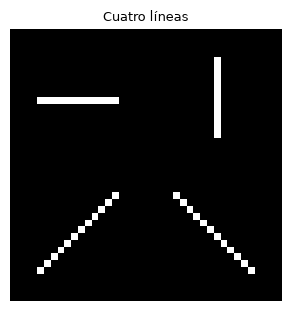

In [17]:
def imagen_lineas(lado: int = 40) -> tuple[np.ndarray, dict[str, np.ndarray]]:
    """Imagen con cuatro líneas, una por cuadrante, y una máscara booleana por cuadrante."""
    A = np.zeros((lado, lado))
    m, a, b = lado // 2, 4, lado // 2 - 4
    A[m // 2, a:b] = 1                                  # horizontal, arriba a la izquierda
    A[a:b, m + m // 2] = 1                              # vertical, arriba a la derecha
    for t in range(a, b):
        A[m + t, m - 1 - t] = 1                         # ascendente /, abajo a la izquierda
        A[m + t, m + t] = 1                             # descendente \, abajo a la derecha
    mascaras = {}
    for nombre, (filas, columnas) in {"horizontal": (slice(0, m), slice(0, m)),
                                      "vertical": (slice(0, m), slice(m, lado)),
                                      "ascendente": (slice(m, lado), slice(0, m)),
                                      "descendente": (slice(m, lado), slice(m, lado))}.items():
        mascara = np.zeros_like(A, dtype=bool)
        mascara[filas, columnas] = True
        mascaras[nombre] = mascara
    return A, mascaras


LINEAS, CUADRANTES = imagen_lineas()
mostrar([LINEAS], ["Cuatro líneas"], columnas=1, lado=3.2)

In [18]:
# Diagonal positiva, fondo negativo: suma total cero.
W_diagonal = np.array([[2., -1., -1.], [-1., 2., -1.], [-1., -1., 2.]])

respuesta máxima, línea horizontal  :   2.00
respuesta máxima, línea vertical    :   2.00
respuesta máxima, línea ascendente  :   2.00
respuesta máxima, línea descendente :   6.00

cociente descendente / mejor de las otras: 3.00
El filtro es selectivo para la diagonal descendente.


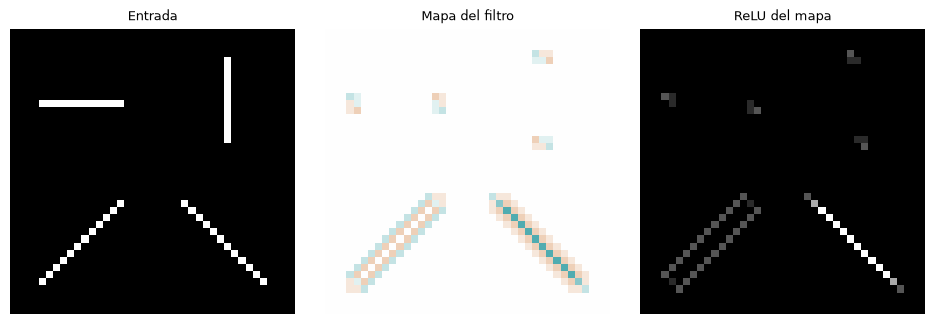

In [19]:
# VERIFICACIÓN
assert np.shape(W_diagonal) == (3, 3), "el filtro debe ser de 3x3"
Z_lineas = convolucion2d(LINEAS, W_diagonal, q=1)
maximos = {nombre: Z_lineas[mascara].max() for nombre, mascara in CUADRANTES.items()}
for nombre, valor in maximos.items():
    print(f"respuesta máxima, línea {nombre:<12}: {valor:6.2f}")
peor_otro = max(v for n, v in maximos.items() if n != "descendente")
cociente = maximos["descendente"] / peor_otro if peor_otro > 0 else np.inf
print(f"\ncociente descendente / mejor de las otras: {cociente:.2f}")
assert maximos["descendente"] > 0, "el filtro no responde positivamente a la diagonal descendente"
assert cociente >= 3, "el filtro no es lo bastante selectivo: el cociente debe ser al menos 3"
print("El filtro es selectivo para la diagonal descendente.")

mostrar([LINEAS, Z_lineas, relu(Z_lineas)], ["Entrada", "Mapa del filtro", "ReLU del mapa"],
        columnas=3, lado=3.2)

El mismo filtro, aplicado sobre la fotografía:

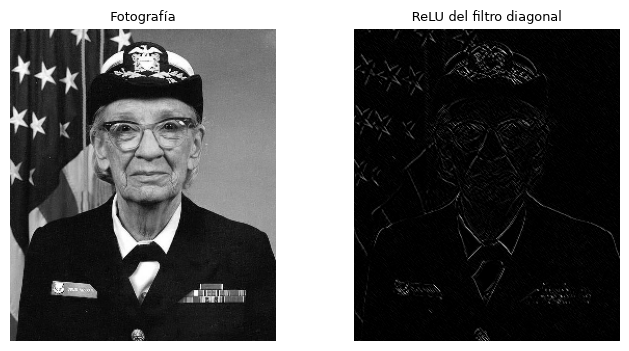

In [20]:
Z_diag_foto = relu(convolucion2d(FOTO, W_diagonal, q=1))
mostrar([FOTO, Z_diag_foto], ["Fotografía", "ReLU del filtro diagonal"], columnas=2, lado=3.6)

### Para analizar

1. Explicar el diseño del filtro: qué hace cada grupo de pesos, y por qué la respuesta a
   las líneas horizontal y vertical es baja.
2. ¿Por qué conviene que los pesos del filtro sumen $0$ (o cerca de $0$)? Considerar qué
   respondería un filtro con todos sus pesos positivos sobre una región clara de la
   fotografía.
3. Sobre la fotografía, ¿en qué regiones responde el filtro? ¿Es un detector útil por sí
   solo, o solo una pieza que combinada con otros filtros sirve para reconocer algo?

**Respuesta:**

1. Los tres pesos 2 de la diagonal suman cuando aparece la diagonal descendente; los seis −1 penalizan brillo fuera de ella. Cada fila y columna suma cero, por lo que una línea horizontal o vertical completa se cancela; sus extremos pueden responder. La diagonal descendente alcanza 6 y las demás orientaciones no superan 2: cociente 3, que cumple la verificación.
2. Los pesos suman cero: una superficie de brillo constante no activa el detector. Con pesos todos positivos, una región clara podría producir una respuesta grande sin contener ninguna diagonal.
3. En la fotografía aparecen respuestas en trazos y segmentos diagonales de contornos, textura y ropa. El filtro no reconoce una persona ni un objeto completo; aporta una característica local que necesita combinarse con otras.

## Ejercicio 7 — Pesos compartidos y traslación

**El mismo filtro se aplica en todas las posiciones.** Esa decisión, los **pesos
compartidos**, tiene dos consecuencias: la convolución es **equivariante a la traslación**
(desplazar la entrada desplaza el mapa en la misma cantidad, § 3.2 de las notas) y la
cantidad de parámetros no depende del tamaño de la imagen.

### 7.1 Max pooling

El *max pooling* resume cada ventana de $r\times r$ por su máximo, con paso $s$. No tiene
parámetros, y su salida tiene lado $\lfloor(d-r)/s\rfloor+1$, la misma fórmula del ejercicio
1 con $q=0$. Corresponde implementarlo.

In [21]:
def max_pooling(A: np.ndarray, r: int = 2, s: int = 2) -> np.ndarray:
    """Max pooling de una entrada de un canal, sin relleno.

    Parámetros
    ----------
    A : arreglo de forma (n_filas, n_columnas).
    r : lado de la ventana.
    s : paso.

    Devuelve
    --------
    P : arreglo de forma (tamano_salida(n_filas, r, s), tamano_salida(n_columnas, r, s))
        con P[u, v] = máximo de A en la ventana de r x r que empieza en (s*u, s*v).
    """
    A = np.asarray(A)
    nf, nc = tamano_salida(A.shape[0], r, s), tamano_salida(A.shape[1], r, s)
    P = np.empty((nf, nc), dtype=A.dtype)
    for u in range(nf):
        for v in range(nc):
            P[u, v] = A[s*u:s*u+r, s*v:s*v+r].max()
    return P

In [22]:
# VERIFICACIÓN
rng = np.random.default_rng(SEMILLA)
for forma, r, s in [((8, 8), 2, 2), ((9, 7), 3, 2), ((10, 10), 3, 3)]:
    A = rng.normal(size=forma)
    P_ref = F.max_pool2d(torch.from_numpy(A)[None, None], kernel_size=r, stride=s)[0, 0].numpy()
    assert np.allclose(max_pooling(A, r, s), P_ref), f"max_pooling: no coincide con PyTorch ({forma}, r={r}, s={s})"
print("max_pooling verificada.")

max_pooling verificada.


### 7.2 Equivarianza e invarianza

El experimento coloca un patrón en forma de X de $5\times5$ en una imagen de $28\times28$, en
tres posiciones distintas, y lo busca con un filtro igual al patrón. Se comprueba:

- que el mapa del filtro se desplaza exactamente lo mismo que el patrón (equivarianza);
- que con paso $s=2$ un desplazamiento de un píxel **no** produce un mapa desplazado;
- que el máximo del mapa después del *pooling* —la respuesta a «¿está el patrón en algún
  lugar?»— no cambia con la posición (invarianza).

Paso 1, desplazamiento (9, 13): mapa desplazado = True
Paso 1, desplazamiento (0, 1):  mapa desplazado = True
Paso 2, desplazamiento (0, 1):  mismo mapa desplazado = False
Patrón en ( 4,  4): forma del pooling (12, 12), máximo 5.76, posición del máximo (np.int64(2), np.int64(2))
Patrón en ( 4,  5): forma del pooling (12, 12), máximo 5.76, posición del máximo (np.int64(2), np.int64(2))
Patrón en (13, 17): forma del pooling (12, 12), máximo 5.76, posición del máximo (np.int64(6), np.int64(8))


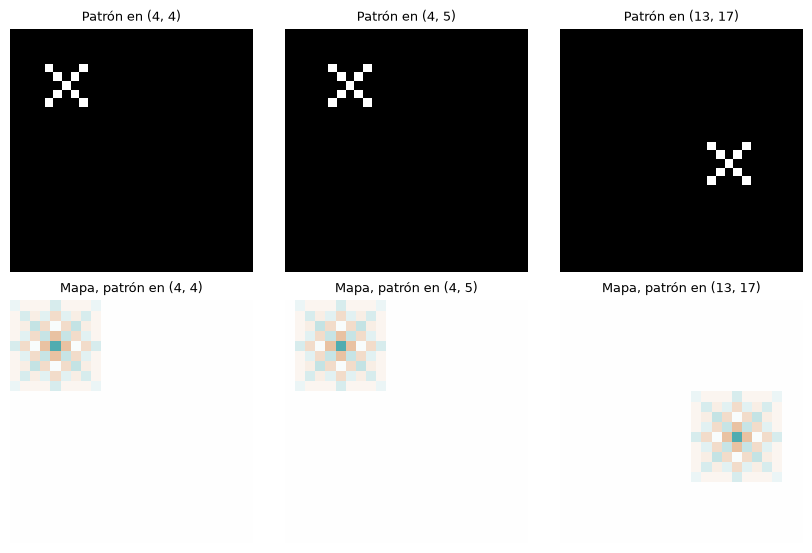

In [23]:
PATRON = np.eye(5) + np.fliplr(np.eye(5))
PATRON[2, 2] = 1.0
W_patron = PATRON - PATRON.mean()          # pesos que suman 0: responde a la forma, no al brillo


def imagen_con_patron(fila: int, columna: int, lado: int = 28) -> np.ndarray:
    A = np.zeros((lado, lado))
    A[fila: fila + 5, columna: columna + 5] = PATRON
    return A


posiciones = [(4, 4), (4, 5), (13, 17)]
imagenes = [imagen_con_patron(f, c) for f, c in posiciones]
mapas = [convolucion2d(A, W_patron) for A in imagenes]

# Equivarianza con paso 1: desplazar la entrada desplaza el mapa.
du, dv = 13 - 4, 17 - 4
print("Paso 1, desplazamiento (9, 13): mapa desplazado =",
      np.allclose(mapas[2][du:, dv:], mapas[0][:-du, :-dv]))
print("Paso 1, desplazamiento (0, 1):  mapa desplazado =",
      np.allclose(mapas[1][:, 1:], mapas[0][:, :-1]))

# Con paso 2, un desplazamiento de un píxel no es un desplazamiento del mapa.
m2 = [convolucion2d(A, W_patron, s=2) for A in imagenes[:2]]
print("Paso 2, desplazamiento (0, 1):  mismo mapa desplazado =",
      any(np.allclose(m2[1][:, k:], m2[0][:, :m2[0].shape[1] - k]) for k in range(3)))

# Invarianza del máximo después del pooling.
for (f, c), Z in zip(posiciones, mapas):
    P = max_pooling(relu(Z))
    print(f"Patrón en ({f:>2}, {c:>2}): forma del pooling {P.shape}, máximo {P.max():.2f}, "
          f"posición del máximo {np.unravel_index(P.argmax(), P.shape)}")

mostrar(imagenes + mapas, [f"Patrón en {p}" for p in posiciones] + [f"Mapa, patrón en {p}" for p in posiciones],
        columnas=3, lado=2.8)

### 7.3 El conteo de parámetros

Una capa densa con $p_0$ entradas y $p_1$ unidades tiene $p_1(p_0+1)$ parámetros: un peso por
par entrada–unidad y un sesgo por unidad. Una capa convolucional con $c_1$ filtros de
$r\times r$ sobre una entrada de $c_0$ canales tiene $c_1(r^2c_0+1)$: cada filtro tiene
$r^2c_0$ pesos y un sesgo, **compartidos en todas las posiciones**. Corresponde implementar
los dos conteos.

In [24]:
def parametros_densa(p_entrada: int, p_salida: int) -> int:
    """Cantidad de parámetros (pesos y sesgos) de una capa densa."""
    return p_salida * (p_entrada + 1)


def parametros_conv(r: int, c_entrada: int, c_salida: int) -> int:
    """Cantidad de parámetros de una capa convolucional con c_salida filtros de r x r x c_entrada."""
    return c_salida * (r*r*c_entrada + 1)

In [25]:
# VERIFICACIÓN
def contar(capa: nn.Module) -> int:
    return sum(t.numel() for t in capa.parameters())


for p0, p1 in [(784, 128), (150_528, 1000), (10, 1)]:
    assert parametros_densa(p0, p1) == contar(nn.Linear(p0, p1)), f"parametros_densa({p0}, {p1})"
for r, c0, c1 in [(3, 1, 32), (5, 3, 64), (11, 3, 96)]:
    assert parametros_conv(r, c0, c1) == contar(nn.Conv2d(c0, c1, kernel_size=r)), f"parametros_conv({r}, {c0}, {c1})"
print("Conteos verificados contra PyTorch.\n")

# Conectar una imagen de d x d x c a 32 mapas del mismo lado.
print(f"{'imagen':>14}{'densa':>18}{'convolucional 3x3':>20}{'cociente':>12}")
for d, c in [(28, 1), (64, 3), (224, 3)]:
    densa = parametros_densa(d * d * c, 32 * d * d)
    conv = parametros_conv(3, c, 32)
    print(f"{f'{d}x{d}x{c}':>14}{densa:>18,}{conv:>20,}{densa / conv:>12,.0f}")

Conteos verificados contra PyTorch.

        imagen             densa   convolucional 3x3    cociente
       28x28x1        19,694,080                 320      61,544
       64x64x3     1,610,743,808                 896   1,797,705
     224x224x3   241,694,179,328                 896 269,747,968


### Para analizar

1. Con paso $1$, el mapa del patrón desplazado es el mapa original desplazado. ¿Qué
   consecuencia tiene eso para el aprendizaje: cuántas veces tiene que aprender la red a
   detectar un patrón que puede aparecer en cualquier lugar de la imagen?
2. ¿Por qué el paso $2$ rompe la equivarianza para un desplazamiento de un píxel?
3. El máximo después del *pooling* no cambió con la posición del patrón. ¿Qué información
   conserva y cuál descarta? ¿Para qué tarea alcanza y para cuál no?
4. Según la tabla, ¿de qué depende la cantidad de parámetros de la capa densa y de qué
   depende la de la capa convolucional? ¿Por qué la segunda no crece con el tamaño de la
   imagen?

**Respuesta:**

1. Aprende un único conjunto de pesos para ese patrón y lo reutiliza en todas las posiciones: no necesita aprender un detector independiente por ubicación. En el experimento, con paso 1, las dos comparaciones de mapas desplazados dan True.
2. El paso 2 evalúa solamente una de cada dos posiciones. Desplazar un píxel cambia la fase de muestreo y no equivale a desplazar un número entero de celdas del mapa. Desplazamientos múltiplos del paso pueden conservar la correspondencia, lejos de los bordes.
3. El máximo global del mapa luego del pooling conserva la fuerza de la mejor coincidencia, pero descarta su ubicación. En las tres posiciones vale 5,76. Sirve para detectar presencia; no alcanza para localizar o segmentar. El mapa completo del pooling sí conserva una ubicación aproximada: no es automáticamente invariante a cualquier traslación.
4. La densa depende del número total de entradas y salidas; conectar todas las posiciones hace crecer rápidamente sus parámetros. La convolucional depende del lado del filtro y los canales de entrada/salida, porque reutiliza los mismos pesos. Con un canal y 32 filtros 3×3 son 320 parámetros, sea cual sea el tamaño espacial de entrada. Su costo computacional y memoria de activaciones sí crecen con la imagen.

---

# Parte 4 — La red aprende los filtros

Hasta acá los filtros se diseñaron a mano. En una red convolucional, los $r^2$ pesos de cada
filtro son parámetros como cualquier otro, ajustados por descenso por gradiente para
reducir la función de costo. Esta parte entrena una red con **una sola capa convolucional**
de ocho filtros de $5\times5$ y la compara con una red densa.

### Los datos: Fashion-MNIST

Fashion-MNIST (Xiao, Rasul y Vollgraf, 2017) tiene $70\,000$ imágenes de $28\times28$ en
escala de grises de prendas de ropa y calzado de diez clases, $60\,000$ de entrenamiento y
$10\,000$ de prueba. Se descarga con `torchvision`, sin credenciales. **Plan B:** si la
descarga falla, se genera un conjunto sintético de cuatro clases (barras horizontales,
barras verticales, diagonales y cruces en posiciones al azar); el resto del laboratorio
funciona igual, aunque los números cambian.

Origen: Fashion-MNIST, descargado con torchvision
Entrenamiento: (60000, 28, 28)   prueba: (10000, 28, 28)   clases: 10


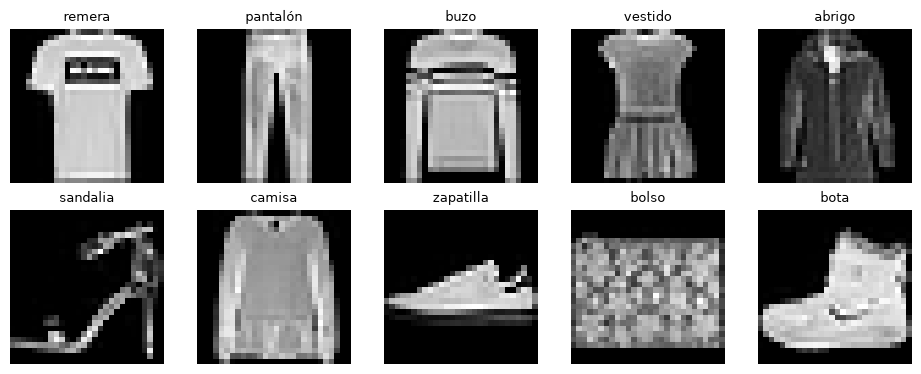

In [26]:
#@title Carga de Fashion-MNIST (ejecutar sin modificar) { display-mode: "form" }
CLASES_FASHION = ["remera", "pantalón", "buzo", "vestido", "abrigo",
                  "sandalia", "camisa", "zapatilla", "bolso", "bota"]


def conjunto_sintetico(n_entrenamiento: int = 12_000, n_prueba: int = 2_000):
    """Plan B sin conexión: cuatro clases de trazos en posiciones al azar, con ruido."""
    rng = np.random.default_rng(SEMILLA)

    def una_imagen(clase: int) -> np.ndarray:
        A = np.zeros((28, 28), dtype=np.float32)
        f, c, largo = rng.integers(4, 12), rng.integers(4, 12), rng.integers(10, 16)
        idx = np.arange(largo)
        if clase in (0, 3):
            A[f + largo // 2, c: c + largo] = 1
        if clase in (1, 3):
            A[f: f + largo, c + largo // 2] = 1
        if clase == 2:
            A[f + idx, c + idx] = 1
        A = ndimage.gaussian_filter(A, 0.6)
        return np.clip(A / A.max() + rng.normal(0, 0.1, A.shape), 0, 1).astype(np.float32)

    def generar(n: int):
        y = rng.integers(0, 4, n)
        return np.stack([una_imagen(k) for k in y]), y

    X_e, y_e = generar(n_entrenamiento)
    X_p, y_p = generar(n_prueba)
    return X_e, y_e, X_p, y_p, ["horizontal", "vertical", "diagonal", "cruz"]


def cargar_fashion_mnist():
    try:
        from torchvision import datasets
        raiz = Path("datos_torchvision")
        entren = datasets.FashionMNIST(raiz, train=True, download=True)
        prueba = datasets.FashionMNIST(raiz, train=False, download=True)
        print("Origen: Fashion-MNIST, descargado con torchvision")
        return (entren.data.numpy().astype(np.float32) / 255, entren.targets.numpy(),
                prueba.data.numpy().astype(np.float32) / 255, prueba.targets.numpy(), CLASES_FASHION)
    except Exception as error:
        print(f"No se pudo descargar Fashion-MNIST ({type(error).__name__}). Plan B: conjunto sintético.")
        return conjunto_sintetico()


X_entren, y_entren, X_prueba, y_prueba, CLASES = cargar_fashion_mnist()
N_CLASES = len(CLASES)
print(f"Entrenamiento: {X_entren.shape}   prueba: {X_prueba.shape}   clases: {N_CLASES}")

ejemplos = [int(np.flatnonzero(y_entren == k)[0]) for k in range(N_CLASES)]
mostrar([X_entren[i] for i in ejemplos], [CLASES[y_entren[i]] for i in ejemplos], columnas=5, lado=1.9)

## Ejercicio 8 — Una red convolucional mínima

Las dos redes que se comparan están dadas:

- **Red convolucional**: una capa convolucional de $c_1=8$ filtros de $5\times5$, ReLU,
  *max pooling* de $2\times2$ con paso $2$, y una capa densa de salida con una unidad por
  clase.
- **Red densa** (perceptrón multicapa): la imagen aplanada en $784$ entradas, una capa
  oculta de $128$ unidades con ReLU y la capa de salida.

Las dos se entrenan con el mismo bucle: entropía cruzada, optimizador Adam y mini-lotes de
$128$ imágenes durante ocho épocas. El lado de los mapas que llegan a la capa de salida se
calcula con `tamano_salida` del ejercicio 1.

In [27]:
D_CONV = tamano_salida(28, r=5)             # lado después de la convolución
D_POOL = tamano_salida(D_CONV, r=2, s=2)    # lado después del pooling
print(f"28 -> convolución 5x5 -> {D_CONV} -> pooling 2x2 -> {D_POOL}")


class RedConvolucional(nn.Module):
    def __init__(self, n_filtros: int = 8, n_clases: int = N_CLASES):
        super().__init__()
        self.conv = nn.Conv2d(1, n_filtros, kernel_size=5)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.salida = nn.Linear(n_filtros * D_POOL * D_POOL, n_clases)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        a = self.pool(torch.relu(self.conv(x)))
        return self.salida(a.flatten(start_dim=1))


class RedDensa(nn.Module):
    def __init__(self, n_ocultas: int = 128, n_clases: int = N_CLASES):
        super().__init__()
        self.oculta = nn.Linear(28 * 28, n_ocultas)
        self.salida = nn.Linear(n_ocultas, n_clases)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.salida(torch.relu(self.oculta(x.flatten(start_dim=1))))


def a_tensor(X: np.ndarray) -> torch.Tensor:
    """Imágenes (n, 28, 28) -> tensor (n, 1, 28, 28), el formato de PyTorch."""
    return torch.from_numpy(X).unsqueeze(1)


def exactitud(modelo: nn.Module, X: np.ndarray, y: np.ndarray) -> float:
    modelo.eval()
    with torch.no_grad():
        predicho = torch.cat([modelo(a_tensor(X[i: i + 2000])).argmax(1)
                              for i in range(0, len(X), 2000)]).numpy()
    return float((predicho == y).mean())


def entrenar(modelo: nn.Module, epocas: int = 8, tasa: float = 2e-3, semilla: int = SEMILLA) -> nn.Module:
    """Entrena con entropía cruzada y Adam; solo ajusta los parámetros con requires_grad."""
    torch.manual_seed(semilla)
    optimizador = torch.optim.Adam([p for p in modelo.parameters() if p.requires_grad], lr=tasa)
    X_t, y_t = a_tensor(X_entren), torch.from_numpy(y_entren).long()
    inicio = time.perf_counter()
    for epoca in range(1, epocas + 1):
        modelo.train()
        orden = torch.randperm(len(X_t))
        for i in range(0, len(X_t), 128):
            lote = orden[i: i + 128]
            optimizador.zero_grad()
            costo = F.cross_entropy(modelo(X_t[lote]), y_t[lote])
            costo.backward()
            optimizador.step()
        print(f"  época {epoca}: exactitud de prueba {exactitud(modelo, X_prueba, y_prueba):.4f}"
              f"   ({time.perf_counter() - inicio:.0f} s)")
    return modelo

28 -> convolución 5x5 -> 24 -> pooling 2x2 -> 12


Antes de entrenar, corresponde **predecir la cantidad de parámetros** de cada red con las
funciones del ejercicio 7. La red convolucional tiene una capa convolucional y una densa; la
red densa, dos capas densas. La verificación compara contra el conteo de PyTorch.

In [28]:
parametros_red_convolucional = parametros_conv(5, 1, 8) + parametros_densa(8 * D_POOL**2, N_CLASES)
parametros_red_densa = parametros_densa(28 * 28, 128) + parametros_densa(128, N_CLASES)

In [29]:
# VERIFICACIÓN
torch.manual_seed(SEMILLA)
red_conv, red_densa = RedConvolucional(), RedDensa()
assert parametros_red_convolucional == contar(red_conv), f"PyTorch cuenta {contar(red_conv)}"
assert parametros_red_densa == contar(red_densa), f"PyTorch cuenta {contar(red_densa)}"
print(f"Red convolucional: {parametros_red_convolucional:>7,} parámetros "
      f"({parametros_conv(5, 1, 8)} en la capa convolucional)")
print(f"Red densa:         {parametros_red_densa:>7,} parámetros")

Red convolucional:  11,738 parámetros (208 en la capa convolucional)
Red densa:         101,770 parámetros


In [30]:
print("Red convolucional")
entrenar(red_conv)
print("Red densa")
entrenar(red_densa)

EXACTITUD = {"convolucional": exactitud(red_conv, X_prueba, y_prueba),
             "densa": exactitud(red_densa, X_prueba, y_prueba)}
print(f"\n{'red':<16}{'parámetros':>12}{'exactitud de prueba':>22}")
for nombre, modelo in [("convolucional", red_conv), ("densa", red_densa)]:
    print(f"{nombre:<16}{contar(modelo):>12,}{EXACTITUD[nombre]:>22.4f}")

Red convolucional
  época 1: exactitud de prueba 0.8537   (2 s)
  época 2: exactitud de prueba 0.8705   (3 s)
  época 3: exactitud de prueba 0.8754   (5 s)
  época 4: exactitud de prueba 0.8808   (7 s)
  época 5: exactitud de prueba 0.8785   (8 s)
  época 6: exactitud de prueba 0.8876   (9 s)
  época 7: exactitud de prueba 0.8883   (11 s)
  época 8: exactitud de prueba 0.8924   (13 s)
Red densa
  época 1: exactitud de prueba 0.8429   (0 s)
  época 2: exactitud de prueba 0.8578   (1 s)
  época 3: exactitud de prueba 0.8552   (1 s)
  época 4: exactitud de prueba 0.8679   (2 s)
  época 5: exactitud de prueba 0.8636   (2 s)
  época 6: exactitud de prueba 0.8757   (2 s)
  época 7: exactitud de prueba 0.8643   (3 s)
  época 8: exactitud de prueba 0.8769   (3 s)

red               parámetros   exactitud de prueba
convolucional         11,738                0.8924
densa                101,770                0.8769


### Para analizar

1. ¿Cuántas veces más parámetros tiene la red densa que la convolucional, y cuál de las dos
   tiene mayor exactitud de prueba? ¿Qué parte de los parámetros de la red convolucional
   está en sus filtros y qué parte en la capa de salida?
2. La capa oculta de la red densa tiene un peso por cada par píxel–unidad. ¿Qué supuesto
   sobre las imágenes **no** hace, que la red convolucional sí hace? ¿Por qué ese supuesto
   permite aprender mejor con menos parámetros?

**Respuesta:**

1. La densa tiene 101,770 parámetros y la convolucional 11,738: 8.67 veces más. Exactitud de prueba: convolucional 89.24%, densa 87.69%; en esta corrida gana la convolucional. Los filtros y sus sesgos suman 208 parámetros (1.77%); la salida tiene 11,530 (98.23%). La mayoría está en la capa densa final.
2. La convolucional supone localidad y reutilización de patrones: píxeles cercanos forman características útiles y el mismo patrón puede aparecer en distintos lugares. La densa no incorpora esas restricciones y aprende un peso independiente por par píxel–unidad. Compartir pesos reduce grados de libertad y aprovecha observaciones del patrón en diferentes posiciones; es una ventaja adecuada para imágenes, no una garantía universal de mayor exactitud.

## Ejercicio 9 — Mirar adentro de la red

Los ocho filtros aprendidos están en `red_conv.conv.weight`, un tensor de forma
`(8, 1, 5, 5)`, y sus sesgos en `red_conv.conv.bias`. Corresponde implementar
`mapas_de_activacion`, que devuelve los ocho mapas **después de la ReLU y antes del
pooling** para una imagen.

La verificación es el punto de llegada del laboratorio: cada mapa de la red tiene que
coincidir con la `convolucion2d` del ejercicio 1 aplicada con el filtro y el sesgo
aprendidos, seguida de la `relu` del ejercicio 5.

In [31]:
def mapas_de_activacion(modelo: RedConvolucional, imagen: np.ndarray) -> np.ndarray:
    """Mapas de la capa convolucional, después de la ReLU, para una imagen.

    Parámetros
    ----------
    modelo : red convolucional entrenada; su capa convolucional es modelo.conv.
    imagen : arreglo de forma (28, 28).

    Devuelve
    --------
    arreglo de NumPy de forma (n_filtros, D_CONV, D_CONV).
    """
    modelo.eval()
    with torch.no_grad():
        entrada = torch.as_tensor(imagen, dtype=modelo.conv.weight.dtype)[None, None]
        return torch.relu(modelo.conv(entrada)).squeeze(0).cpu().numpy()

In [32]:
# VERIFICACIÓN
FILTROS_APRENDIDOS = red_conv.conv.weight.detach().numpy()[:, 0]     # (8, 5, 5)
SESGOS_APRENDIDOS = red_conv.conv.bias.detach().numpy()               # (8,)

imagen = X_prueba[int(np.flatnonzero(y_prueba == N_CLASES - 1)[0])]
mapas_red = mapas_de_activacion(red_conv, imagen)
assert mapas_red.shape == (8, D_CONV, D_CONV), f"forma {mapas_red.shape}"
for j in range(8):
    propio = relu(convolucion2d(imagen.astype(float), FILTROS_APRENDIDOS[j].astype(float),
                                b=float(SESGOS_APRENDIDOS[j])))
    assert np.allclose(propio, mapas_red[j], atol=1e-5), f"el mapa {j} no coincide con convolucion2d"
print("Los ocho mapas de la red coinciden con convolucion2d + relu del propio laboratorio.")

Los ocho mapas de la red coinciden con convolucion2d + relu del propio laboratorio.


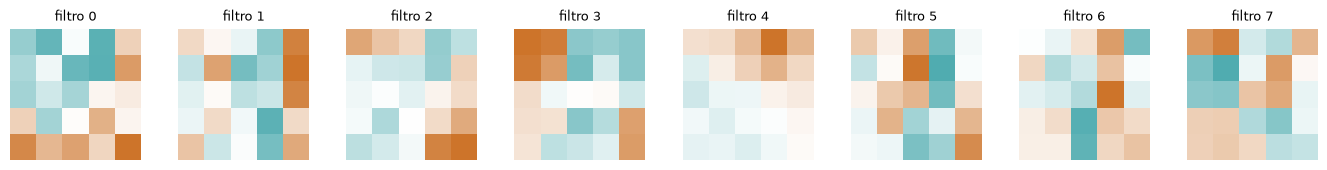

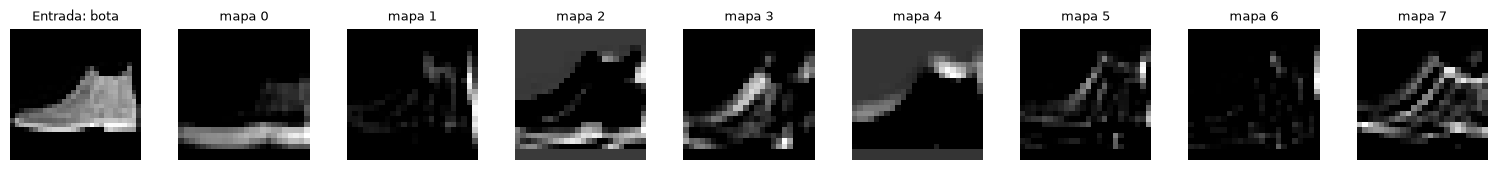

In [33]:
mostrar(list(FILTROS_APRENDIDOS), [f"filtro {j}" for j in range(8)], columnas=8, lado=1.7)
mostrar([imagen] + list(mapas_red), [f"Entrada: {CLASES[N_CLASES - 1]}"] + [f"mapa {j}" for j in range(8)],
        columnas=9, lado=1.7)

### Para analizar

1. Comparar los ocho filtros aprendidos con los de la galería del ejercicio 3. ¿Alguno se
   parece a un detector de bordes (columnas o filas de signo opuesto), a un suavizado o a un
   detector de diagonales? ¿Aparecen pares de filtros de signo opuesto, como anticipaba el
   ejercicio 5?
2. En los mapas de la imagen, ¿qué partes del objeto resalta cada filtro: contornos de una
   orientación, regiones claras, regiones oscuras?
3. Nadie le indicó a la red que buscara bordes. ¿Por qué el descenso por gradiente termina
   produciendo filtros de ese tipo?

**Respuesta:**

1. Los filtros aprendidos mezclan regiones de pesos positivos y negativos y no tienen por qué coincidir con los filtros clásicos ni sumar 0 o 1. Comparación por coseno entre sus pesos y los de la galería 5×5: filtro 0: mayor similitud absoluta con promedio (coseno +0.30); filtro 1: mayor similitud absoluta con prewitt_vertical (coseno -0.42); filtro 2: mayor similitud absoluta con promedio (coseno +0.23); filtro 3: mayor similitud absoluta con prewitt_vertical (coseno -0.21); filtro 4: mayor similitud absoluta con prewitt_horizontal (coseno -0.33); filtro 5: mayor similitud absoluta con prewitt_vertical (coseno -0.45); filtro 6: mayor similitud absoluta con prewitt_vertical (coseno +0.40); filtro 7: mayor similitud absoluta con prewitt_vertical (coseno +0.31). Es una descripción aproximada, no una identificación exacta. El par más opuesto es 0–4, coseno -0.37; pueden aparecer polaridades complementarias sin que sean negativos exactos.
2. Sobre la bota, el mapa 0 destaca sobre todo la franja de la suela; los mapas 1 y 5 muestran detalles del borde derecho y trazos internos; el 2 responde ampliamente al fondo y también a la zona de la suela; el 3 destaca la parte diagonal del empeine; el 4 responde al fondo superior y al contorno alto; el 6 tiene pocas activaciones, principalmente en el borde derecho; el 7 destaca varios contornos y diagonales de la prenda. La ubicación de la activación se lee en los mapas, no solamente en los pesos. Fracción de posiciones positivas por filtro 0–7: 30.9%, 26.9%, 63.4%, 36.5%, 59.5%, 34.9%, 57.3%, 42.2%. Un mapa muy extendido puede captar una región y su sesgo, mientras otro más disperso responde a detalles; ninguna activación aislada significa directamente “bota”.
3. El gradiente de la pérdida modifica los pesos que ayudan a separar las clases. Bordes y trazos son estructuras locales frecuentes que distinguen prendas; por eso pueden surgir detectores similares sin etiquetas explícitas de bordes. Los aprende para clasificación, no para reproducir un operador clásico.

## Ejercicio 10 — Filtros fijos contra filtros aprendidos

Si los filtros de la galería ya detectan bordes, ¿hace falta aprenderlos? El experimento
entrena tres redes con la misma arquitectura del ejercicio 8, que difieren solo en la capa
convolucional:

- **aprendidos**: la red del ejercicio 8, con los filtros ajustados por el entrenamiento;
- **galería, congelados**: los ocho filtros del ejercicio 3, fijos; solo se entrena la capa
  de salida;
- **aleatorios, congelados**: ocho filtros con la inicialización al azar de PyTorch, fijos;
  solo se entrena la capa de salida.

La capa convolucional de la red tiene filtros de $5\times5$; los filtros de $3\times3$ de la
galería se completan con un borde de ceros, lo que no cambia su respuesta. Corresponde
implementar `filtros_de_la_galeria`.

In [34]:
def filtros_de_la_galeria() -> np.ndarray:
    """Los ocho filtros de FILTROS, en su orden, llevados a 5 x 5 con un borde de ceros.

    Devuelve
    --------
    arreglo float32 de forma (8, 1, 5, 5), el formato de red_conv.conv.weight.
    """
    pesos = []
    for W in FILTROS.values():
        margen = (5 - W.shape[0]) // 2
        pesos.append(np.pad(W, ((margen, margen), (margen, margen))))
    return np.asarray(pesos, dtype=np.float32)[:, None, :, :]

In [35]:
# VERIFICACIÓN
W_galeria = filtros_de_la_galeria()
assert W_galeria.shape == (8, 1, 5, 5) and W_galeria.dtype == np.float32, f"forma {W_galeria.shape}, tipo {W_galeria.dtype}"
assert np.allclose(W_galeria[4, 0, 1:4, 1:4], FILTROS["prewitt_vertical"]) and W_galeria[4, 0, 0].sum() == 0
assert np.allclose(W_galeria[2, 0], FILTROS["gaussiano"])
print("filtros_de_la_galeria verificada.")


def red_con_filtros_congelados(pesos: np.ndarray | None, semilla: int = SEMILLA) -> RedConvolucional:
    torch.manual_seed(semilla)
    red = RedConvolucional()
    if pesos is not None:
        red.conv.weight.data = torch.from_numpy(pesos)
        red.conv.bias.data.zero_()
    red.conv.weight.requires_grad_(False)
    red.conv.bias.requires_grad_(False)
    return red


print("\nGalería, congelados")
red_galeria = entrenar(red_con_filtros_congelados(W_galeria))
print("Aleatorios, congelados")
red_aleatoria = entrenar(red_con_filtros_congelados(None))

assert np.allclose(red_galeria.conv.weight.detach().numpy(), W_galeria), "los filtros congelados cambiaron"

EXACTITUD["galería, congelados"] = exactitud(red_galeria, X_prueba, y_prueba)
EXACTITUD["aleatorios, congelados"] = exactitud(red_aleatoria, X_prueba, y_prueba)
print(f"\n{'filtros':<26}{'parámetros entrenados':>22}{'exactitud de prueba':>22}")
for nombre, modelo in [("convolucional", red_conv), ("galería, congelados", red_galeria),
                       ("aleatorios, congelados", red_aleatoria), ("densa", red_densa)]:
    entrenados = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"{nombre:<26}{entrenados:>22,}{EXACTITUD[nombre]:>22.4f}")

filtros_de_la_galeria verificada.

Galería, congelados
  época 1: exactitud de prueba 0.8586   (1 s)
  época 2: exactitud de prueba 0.8635   (2 s)
  época 3: exactitud de prueba 0.8595   (3 s)
  época 4: exactitud de prueba 0.8661   (5 s)
  época 5: exactitud de prueba 0.8662   (6 s)
  época 6: exactitud de prueba 0.8711   (7 s)
  época 7: exactitud de prueba 0.8647   (8 s)
  época 8: exactitud de prueba 0.8739   (9 s)
Aleatorios, congelados
  época 1: exactitud de prueba 0.8124   (1 s)
  época 2: exactitud de prueba 0.8359   (2 s)
  época 3: exactitud de prueba 0.8435   (3 s)
  época 4: exactitud de prueba 0.8508   (4 s)
  época 5: exactitud de prueba 0.8543   (5 s)
  época 6: exactitud de prueba 0.8575   (6 s)
  época 7: exactitud de prueba 0.8613   (7 s)
  época 8: exactitud de prueba 0.8621   (8 s)

filtros                    parámetros entrenados   exactitud de prueba
convolucional                             11,738                0.8924
galería, congelados                       1

### Para analizar

1. Ordenar las tres variantes convolucionales por exactitud. ¿Cuánto se gana al aprender los
   filtros respecto de usar los de la galería? ¿Y respecto de filtros al azar?
2. Los filtros al azar congelados, ¿son inútiles? ¿Qué hace la capa de salida con sus mapas?
3. Los filtros de la galería fueron diseñados por personas para detectar bordes. ¿Por qué
   pueden ser peores que filtros aprendidos en ocho épocas? Considerar para qué
   fue optimizado cada conjunto de filtros.

**Respuesta:**

1. Orden observado: convolucional (89.24%) > galería, congelados (87.39%) > aleatorios, congelados (86.21%). Aprender los filtros cambia la exactitud en +1.85 puntos porcentuales frente a la galería y +3.03 frente a los aleatorios. No se cambió el número de épocas para favorecer una variante.
2. Los filtros aleatorios no son necesariamente inútiles: generan respuestas locales distintas y ReLU las transforma. La capa de salida puede aprender a combinar las que correlacionan con cada clase, aunque la representación no se adapte a la tarea.
3. La galería fue diseñada para suavizar, realzar o detectar diferencias de brillo; los filtros aprendidos minimizan directamente el error de clasificación. Además, las escalas y sesgos iniciales difieren entre variantes, por lo que esta comparación no aísla exclusivamente el tipo de patrón. Un único entrenamiento por variante no demuestra una superioridad estadística universal.

## Ejercicio 11 (opcional) — Traslaciones: red convolucional contra red densa

Las imágenes de Fashion-MNIST están centradas. El experimento desplaza las imágenes de
prueba entre $0$ y $5$ píxeles hacia la derecha (rellenando con ceros) y mide la exactitud de
las dos redes del ejercicio 8, **sin reentrenarlas**.

 desplazamiento       0       1       2       3       4       5
  convolucional   0.892   0.850   0.682   0.354   0.241   0.205
          densa   0.877   0.791   0.568   0.381   0.287   0.243


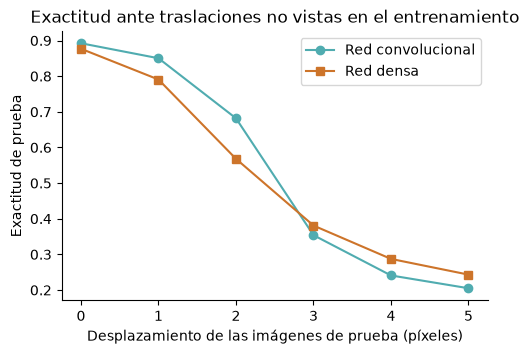

In [36]:
def desplazar(X: np.ndarray, k: int) -> np.ndarray:
    """Desplaza las imágenes k columnas a la derecha, rellenando con ceros."""
    if k == 0:
        return X
    Y = np.zeros_like(X)
    Y[:, :, k:] = X[:, :, :-k]
    return Y


desplazamientos = range(0, 6)
curvas = {nombre: [exactitud(modelo, desplazar(X_prueba, k), y_prueba) for k in desplazamientos]
          for nombre, modelo in [("convolucional", red_conv), ("densa", red_densa)]}

print(f"{'desplazamiento':>15}" + "".join(f"{k:>8}" for k in desplazamientos))
for nombre, valores in curvas.items():
    print(f"{nombre:>15}" + "".join(f"{v:>8.3f}" for v in valores))

plt.figure(figsize=(5.5, 3.5))
plt.plot(desplazamientos, curvas["convolucional"], "o-", color=TURQUESA, label="Red convolucional")
plt.plot(desplazamientos, curvas["densa"], "s-", color=NARANJA, label="Red densa")
plt.xlabel("Desplazamiento de las imágenes de prueba (píxeles)")
plt.ylabel("Exactitud de prueba")
plt.title("Exactitud ante traslaciones no vistas en el entrenamiento")
plt.legend()
plt.show()

### Para analizar

1. ¿Cuál de las dos redes pierde menos exactitud con desplazamientos chicos y cuál con
   desplazamientos grandes?
2. La capa convolucional es equivariante a la traslación (ejercicio 7). ¿Por qué entonces la
   red convolucional **completa** también pierde exactitud? Identificar qué parte de la red
   no es equivariante.
3. ¿Qué cambio en el entrenamiento —no en la arquitectura— atacaría este problema?

**Respuesta:**

1. Con un píxel pierde menos la convolucional; las caídas son 4.21 y 8.63 puntos porcentuales para convolucional y densa. Con cinco píxeles pierde menos la densa; las caídas son 68.74 y 63.37 puntos. La comparación depende del tamaño del desplazamiento.
2. La convolución con paso 1 desplaza sus mapas, pero el pooling de paso 2 cambia la fase para traslaciones impares. Además, aplanar y conectar con una capa densa asigna pesos distintos a cada posición y no produce una clasificación invariante. Los bordes y el recorte de parte del objeto al desplazar también cambian la información disponible.
3. Entrenar con aumentos de datos: traslaciones aleatorias que conservan la clase, aplicadas solo a entrenamiento. La exploración siguiente lo comprueba con movimientos de −3 a +3 píxeles. No se incorporan imágenes ni etiquetas de prueba al entrenamiento.

---

## Cierre

### Para analizar

Responder en una o dos líneas cada una, con un número de este notebook como evidencia.

1. ¿Qué es un filtro, y qué registra el mapa de activación que produce?
2. ¿Qué dos supuestos sobre las imágenes hace una capa convolucional, y qué ganancia concreta
   produce cada uno?
3. ¿Qué diferencia a una red convolucional de un banco de filtros diseñados a mano?

**Respuesta:**

1. Un filtro es un arreglo de pesos compartidos que compara ventanas locales; su mapa registra fuerza y ubicación de la respuesta. El detector diagonal obtuvo 6 frente a un máximo 2 en las demás orientaciones.
2. Localidad reduce las conexiones a un vecindario; compartir pesos reutiliza el detector en toda la imagen. La capa 5×5, de 1 a 8 canales, necesita solo 208 parámetros y desplaza su mapa con el patrón.
3. La red ajusta sus filtros para reducir la pérdida de clasificación. En esta corrida obtuvo 89.24%, frente a 87.39% con la galería fija; el banco manual conserva los operadores elegidos a priori.

---

## Para seguir explorando

Fuera del tiempo de clase, sin obligación y sin evaluación:

- **Aumento de datos.** Repetir el ejercicio 11 con la red convolucional entrenada sobre
  imágenes desplazadas al azar entre $-3$ y $3$ píxeles. ¿Cambia la curva? ¿Y la exactitud
  sin desplazar?
- **Una segunda capa.** Agregar una segunda capa convolucional de $16$ filtros de $3\times3$
  con su ReLU y su *pooling*. Calcular con `tamano_salida` el lado de los mapas que llegan a
  la capa de salida y con `parametros_conv` la cantidad de parámetros. ¿Cuánto de la imagen
  original ve cada unidad de la segunda capa (su campo receptivo)?
- **Cuántos filtros.** Entrenar la red del ejercicio 8 con $2$, $4$, $8$, $16$ y $32$
  filtros y graficar la exactitud de prueba contra la cantidad de parámetros, junto al punto
  de la red densa.

### Exploración 1 — Aumento de datos
Se entrenan ocho épocas con el mismo optimizador, tasa y mini-lotes. Cada imagen de entrenamiento recibe una traslación aleatoria entre −3 y +3 píxeles en ambos ejes en cada época, con ceros en el borde y sin envolver la imagen. El test no participa en el entrenamiento.

Las curvas de test de este laboratorio son comparaciones exploratorias con un presupuesto fijado de antemano. No se elige una época o configuración ganadora usando el test; para seleccionar hiperparámetros haría falta separar validación del conjunto de entrenamiento y reservar otro test final.

  época 1: entrenamiento con traslaciones aleatorias completado
  época 2: entrenamiento con traslaciones aleatorias completado
  época 3: entrenamiento con traslaciones aleatorias completado
  época 4: entrenamiento con traslaciones aleatorias completado
  época 5: entrenamiento con traslaciones aleatorias completado
  época 6: entrenamiento con traslaciones aleatorias completado
  época 7: entrenamiento con traslaciones aleatorias completado
  época 8: entrenamiento con traslaciones aleatorias completado
píxeles               [0, 1, 2, 3, 4, 5]
sin aumento           [0.8924, 0.8503, 0.6818, 0.3539, 0.2409, 0.205]
con aumento           [0.8405, 0.8356, 0.8352, 0.8196, 0.6985, 0.437]


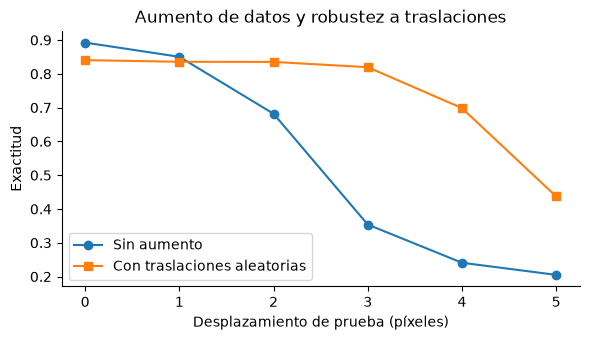

In [37]:
def trasladar_lote(lote: torch.Tensor, limite: int = 3) -> torch.Tensor:
    n, _, h, w = lote.shape
    movimientos = torch.randint(-limite, limite + 1, (n, 2))
    filas = torch.arange(h)[None, :, None] - movimientos[:, 0, None, None]
    columnas = torch.arange(w)[None, None, :] - movimientos[:, 1, None, None]
    valido = (filas >= 0) & (filas < h) & (columnas >= 0) & (columnas < w)
    valores = lote[torch.arange(n)[:, None, None], 0, filas.clamp(0, h-1), columnas.clamp(0, w-1)]
    return (valores * valido).unsqueeze(1)


def entrenar_aumentada(modelo: nn.Module, epocas: int = 8) -> nn.Module:
    torch.manual_seed(SEMILLA)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=2e-3)
    X_t, y_t = a_tensor(X_entren), torch.from_numpy(y_entren).long()
    for epoca in range(1, epocas + 1):
        modelo.train()
        orden = torch.randperm(len(X_t))
        for i in range(0, len(X_t), 128):
            indices = orden[i:i+128]
            optimizador.zero_grad()
            costo = F.cross_entropy(modelo(trasladar_lote(X_t[indices])), y_t[indices])
            costo.backward()
            optimizador.step()
        print(f"  época {epoca}: entrenamiento con traslaciones aleatorias completado")
    return modelo


torch.manual_seed(SEMILLA)
red_aumentada = entrenar_aumentada(RedConvolucional())
curva_aumentada = [exactitud(red_aumentada, desplazar(X_prueba, k), y_prueba) for k in desplazamientos]
print("píxeles              ", list(desplazamientos))
print("sin aumento          ", np.round(curvas['convolucional'], 4).tolist())
print("con aumento          ", np.round(curva_aumentada, 4).tolist())
plt.figure(figsize=(6, 3.5))
plt.plot(desplazamientos, curvas['convolucional'], 'o-', label='Sin aumento')
plt.plot(desplazamientos, curva_aumentada, 's-', label='Con traslaciones aleatorias')
plt.xlabel('Desplazamiento de prueba (píxeles)')
plt.ylabel('Exactitud')
plt.title('Aumento de datos y robustez a traslaciones')
plt.legend(); plt.tight_layout(); plt.show()

**Resultado:** sin desplazar, la exactitud pasa de 89.24% a 84.05%; con 3 píxeles, de 35.39% a 81.96%; con 5, de 20.50% a 43.70%. El aumento enseña a reconocer el objeto en posiciones distintas; el resultado sobre 5 píxeles también evalúa un desplazamiento mayor que los +3 vistos durante entrenamiento. No convierte la arquitectura en exactamente invariante ni recupera píxeles recortados.

### Exploración 2 — Una segunda capa
Secuencia: convolución 5×5 de 8 filtros → ReLU → pooling 2×2 → convolución 3×3 de 16 filtros → ReLU → pooling 2×2 → salida densa. Se mantienen ocho épocas y el resto del entrenamiento.

El campo receptivo se calcula con `R_n = R_anterior + (r−1)·salto_anterior`: la primera convolución ve 5×5; el primer pooling, 6×6 con salto 2; la segunda convolución, **10×10**. Tras su pooling, cada unidad resume **12×12** de la entrada, con salto 4.

In [38]:
D_CONV2 = tamano_salida(D_POOL, r=3)
D_POOL2 = tamano_salida(D_CONV2, r=2, s=2)


class RedDosCapas(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, kernel_size=5)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3)
        self.pool = nn.MaxPool2d(2)
        self.salida = nn.Linear(16 * D_POOL2**2, N_CLASES)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        return self.salida(x.flatten(start_dim=1))


parametros_dos_capas = parametros_conv(5, 1, 8) + parametros_conv(3, 8, 16) + parametros_densa(16 * D_POOL2**2, N_CLASES)
torch.manual_seed(SEMILLA)
red_dos_capas = RedDosCapas()
assert contar(red_dos_capas) == parametros_dos_capas
print(f"Lados: 28 → {D_CONV} → {D_POOL} → {D_CONV2} → {D_POOL2}")
print('Parámetros segunda convolución:', parametros_conv(3, 8, 16))
print('Parámetros totales:', parametros_dos_capas)
entrenar(red_dos_capas)
exactitud_dos_capas = exactitud(red_dos_capas, X_prueba, y_prueba)
print('Exactitud segunda capa:', round(exactitud_dos_capas, 4))

Lados: 28 → 24 → 12 → 10 → 5
Parámetros segunda convolución: 1168
Parámetros totales: 5386
  época 1: exactitud de prueba 0.8244   (2 s)
  época 2: exactitud de prueba 0.8501   (4 s)
  época 3: exactitud de prueba 0.8581   (6 s)
  época 4: exactitud de prueba 0.8603   (8 s)
  época 5: exactitud de prueba 0.8605   (10 s)
  época 6: exactitud de prueba 0.8736   (13 s)
  época 7: exactitud de prueba 0.8727   (15 s)
  época 8: exactitud de prueba 0.8750   (17 s)
Exactitud segunda capa: 0.875


**Resultado:** los lados son 28 → 24 → 12 → 10 → 5. La segunda convolución tiene 1.168 parámetros y el modelo completo 5.386, frente a 11.738 de una sola capa: el segundo pooling reduce mucho las entradas a la salida densa. La exactitud pasa de 89.24% a 87.50%. La segunda capa combina patrones locales de la primera y amplía el campo receptivo; más profundidad no implica necesariamente más parámetros totales ni una mejora garantizada.

### Exploración 3 — Cuántos filtros
Se entrenan 2, 4, 8, 16 y 32 filtros con la misma semilla y ocho épocas. Para 8 se reutiliza el modelo del ejercicio 8. Se cuenta tanto la convolución como la capa densa de salida: aumentar canales también aumenta las entradas de esa capa. Cada punto corresponde a una sola corrida, por lo que diferencias pequeñas requieren repetición con otras semillas.


Entrenamiento con 2 filtros
  época 1: exactitud de prueba 0.7861   (1 s)
  época 2: exactitud de prueba 0.8127   (2 s)
  época 3: exactitud de prueba 0.8174   (2 s)
  época 4: exactitud de prueba 0.8338   (3 s)
  época 5: exactitud de prueba 0.8343   (4 s)
  época 6: exactitud de prueba 0.8456   (5 s)
  época 7: exactitud de prueba 0.8378   (5 s)
  época 8: exactitud de prueba 0.8503   (6 s)

Entrenamiento con 4 filtros
  época 1: exactitud de prueba 0.8363   (1 s)
  época 2: exactitud de prueba 0.8520   (2 s)
  época 3: exactitud de prueba 0.8607   (3 s)
  época 4: exactitud de prueba 0.8635   (4 s)
  época 5: exactitud de prueba 0.8639   (5 s)
  época 6: exactitud de prueba 0.8705   (6 s)
  época 7: exactitud de prueba 0.8756   (7 s)
  época 8: exactitud de prueba 0.8763   (8 s)

Entrenamiento con 16 filtros
  época 1: exactitud de prueba 0.8669   (2 s)
  época 2: exactitud de prueba 0.8886   (5 s)
  época 3: exactitud de prueba 0.8923   (7 s)
  época 4: exactitud de prueba 0.8941 

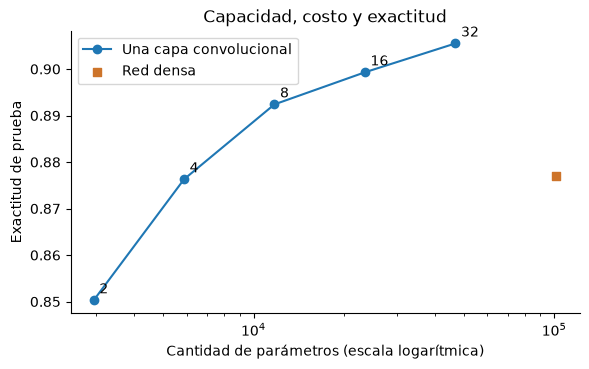

In [39]:
resultados_filtros = []
for cantidad in [2, 4, 8, 16, 32]:
    if cantidad == 8:
        modelo = red_conv
    else:
        torch.manual_seed(SEMILLA)
        modelo = RedConvolucional(n_filtros=cantidad)
        print(f"\nEntrenamiento con {cantidad} filtros")
        entrenar(modelo)
    parametros = parametros_conv(5, 1, cantidad) + parametros_densa(cantidad * D_POOL**2, N_CLASES)
    assert parametros == contar(modelo)
    resultados_filtros.append({'filtros': cantidad, 'parametros': parametros, 'exactitud': exactitud(modelo, X_prueba, y_prueba)})

print(f"{'filtros':>10}{'parámetros':>15}{'exactitud':>15}")
for fila in resultados_filtros:
    print(f"{fila['filtros']:>10}{fila['parametros']:>15,}{fila['exactitud']:>15.4f}")
plt.figure(figsize=(6, 3.8))
plt.plot([f['parametros'] for f in resultados_filtros], [f['exactitud'] for f in resultados_filtros], 'o-', label='Una capa convolucional')
for fila in resultados_filtros:
    plt.annotate(str(fila['filtros']), (fila['parametros'], fila['exactitud']), xytext=(4, 5), textcoords='offset points')
plt.scatter([parametros_red_densa], [EXACTITUD['densa']], marker='s', color=NARANJA, label='Red densa')
plt.xscale('log')
plt.xlabel('Cantidad de parámetros (escala logarítmica)')
plt.ylabel('Exactitud de prueba')
plt.title('Capacidad, costo y exactitud')
plt.legend(); plt.tight_layout(); plt.show()

**Resultado:** el valor más alto observado en el barrido corresponde a 32 filtros, 46,922 parámetros y 90.55% de exactitud. Es un resultado descriptivo del test, no una selección validada de hiperparámetros. La cantidad de parámetros crece como `1.466·n_filtros + 10`; más filtros amplían los patrones posibles y el costo, pero no garantizan mejoras proporcionales. Para elegir cuántos usar conviene comparar también validación, tiempo y variación entre semillas.